# AAAC: Main Experiments — Task B (Adversarial Detection)

**Purpose**: Train all five models (MARBERT, AraBERT, DziriBERT, SVM, RandomForest) on **Task B only** (binary benign vs. harmful). Compute bootstrap 95% CIs, run McNemar's paired significance tests (Holm-corrected), export per-class P/R tables, and generate the summary tables and visualizations.


## 1. Setup & Install

In [ ]:

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  

!pip install -q pyarabic arabert

import sys
if any(m in sys.modules for m in ("torch", "transformers")):
    print("⚠ torch/transformers already imported in this session -> restart the session, then run all cells from the top.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 3.7 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 4.2 MB/s eta 0:00:00ta 0:00:01


In [ ]:
%matplotlib inline
import os, re, json, random, warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import torch
from torch.utils.data import Dataset

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report, cohen_kappa_score
)
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, EarlyStoppingCallback,
    DataCollatorWithPadding
)
import joblib, pyarabic.araby as araby

# ── Config ──────────────────────────────────────────────────────────────────
import glob
def find_input(fname):
    hits = sorted(glob.glob(f"/kaggle/input/**/{fname}", recursive=True))
    if not hits:
        raise FileNotFoundError(f"{fname} not found under /kaggle/input -> add the AAAC dataset via 'Add Input'.")
    return hits[0]

TRAIN_PATH    = find_input("train_aaac_final.csv")
VAL_PATH      = find_input("val_aaac_final.csv")
TEST_PATH     = find_input("test_aaac_final.csv")
TEXT_COL      = "text"
SEED          = 42
N_SEEDS       = 5          # training seeds (42..46) for mean ± std
BOOTSTRAP_N   = 1000       # bootstrap resamples for 95% CI
MAX_LENGTH    = 128        # dynamic padding is used, so a larger cap costs no extra compute
BATCH_SIZE    = 16
EPOCHS        = 8          # best epoch picked on VALIDATION macro-F1 (early stopping, patience 2)
LEARNING_RATE = 3e-5
WARMUP_RATIO  = 0.1
WEIGHT_DECAY  = 0.01
USE_ARABERT_PREPROCESSOR = True   # AraBERT v02 expects its own preprocessing

# transformers v5 removed `warmup_ratio` (use a float `warmup_steps` < 1 = ratio of total steps);
# v4 still needs `warmup_ratio`. Pick whichever this install supports.
import inspect
WARMUP_KW = ({"warmup_ratio": WARMUP_RATIO}
             if "warmup_ratio" in inspect.signature(TrainingArguments.__init__).parameters
             else {"warmup_steps": WARMUP_RATIO})
DEVICE        = "cuda" if torch.cuda.is_available() else "cpu"

OUTPUT_DIR  = "/kaggle/working/outputs"   # everything under /kaggle/working is kept as notebook output
MODELS_DIR  = "/kaggle/working/models"    # small: only the TF-IDF vectorizers / ML baselines (transformer weights are never saved)
FIGS_DIR    = f"{OUTPUT_DIR}/figures/nb2_experiments"
RESULTS_DIR = f"{OUTPUT_DIR}/results"
for d in [OUTPUT_DIR, MODELS_DIR, FIGS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

TASKS = {
    "adversarial": {"label_col": "is_adversarial", "name": "Adversarial Detection"},
}
TRANSFORMER_MODELS = {
    "MARBERT":   "UBC-NLP/MARBERT",
    "AraBERT":   "aubmindlab/bert-base-arabertv02",
    "DziriBERT": "alger-ia/dziribert",
}

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Config loaded. Device:", DEVICE)


Config loaded. Device: cuda


In [3]:
# Record the environment, settings and DATA FILE FINGERPRINTS (for the paper's reproducibility statement)
import sys, platform, hashlib, importlib.metadata as md
RUN_TAG = "adversarial"
env = {
    "run": RUN_TAG,
    "python": sys.version.split()[0], "platform": platform.platform(), "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "seed": SEED, "n_seeds": N_SEEDS,
    "settings": {"max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "epochs_max": EPOCHS,
                 "learning_rate": LEARNING_RATE, "warmup_ratio": WARMUP_RATIO, "weight_decay": WEIGHT_DECAY,
                 "arabert_preprocessor": USE_ARABERT_PREPROCESSOR, "bootstrap_n": BOOTSTRAP_N,
                 "model_selection": "best epoch on validation macro-F1 (early stopping, patience 2)"},
    "checkpoints": TRANSFORMER_MODELS,
}
for pkg in ["torch", "transformers", "accelerate", "scikit-learn", "numpy", "pandas", "scipy",
            "statsmodels", "pyarabic", "arabert"]:
    try:    env[pkg] = md.version(pkg)
    except Exception: env[pkg] = None

# Which data files did THIS run read? (Task A and Task B must use identical files.)
env["data_files"] = {}
for _name, _p in [("train", TRAIN_PATH), ("val", VAL_PATH), ("test", TEST_PATH)]:
    with open(_p, "rb") as _f:
        env["data_files"][_name] = {"sha256_16": hashlib.sha256(_f.read()).hexdigest()[:16], "rows": int(len(pd.read_csv(_p)))}
_tr = pd.read_csv(TRAIN_PATH)
_c = _tr.loc[_tr["id"] == "case_0369", "text"]
env["case_0369_has_arabic_script"] = bool(re.search(r"[\u0600-\u06FF]", _c.iloc[0])) if len(_c) else None

for _fn in (f"{RESULTS_DIR}/environment.json", f"{RESULTS_DIR}/environment_{RUN_TAG}.json"):
    with open(_fn, "w") as f:
        json.dump(env, f, indent=2)
print(json.dumps(env, indent=2))
print("\n>>> data_files + case_0369_has_arabic_script must be IDENTICAL in environment_intent.json and environment_adversarial.json")

{
  "run": "adversarial",
  "python": "3.13.15",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "device": "cuda",
  "gpu": "Tesla T4",
  "seed": 42,
  "n_seeds": 5,
  "settings": {
    "max_length": 128,
    "batch_size": 16,
    "epochs_max": 8,
    "learning_rate": 3e-05,
    "warmup_ratio": 0.1,
    "weight_decay": 0.01,
    "arabert_preprocessor": true,
    "bootstrap_n": 1000,
    "model_selection": "best epoch on validation macro-F1 (early stopping, patience 2)"
  },
  "checkpoints": {
    "MARBERT": "UBC-NLP/MARBERT",
    "AraBERT": "aubmindlab/bert-base-arabertv02",
    "DziriBERT": "alger-ia/dziribert"
  },
  "torch": "2.11.0+cu128",
  "transformers": "5.16.1",
  "accelerate": "1.14.0",
  "scikit-learn": "1.6.1",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scipy": "1.16.3",
  "statsmodels": "0.15.0",
  "pyarabic": "0.6.15",
  "arabert": "1.0.1",
  "data_files": {
    "train": {
      "sha256_16": "4b96196a77c321b1",
      "rows": 2472
    },
    "val": {
      "sha256

## 2. Load & Preprocess Data

In [4]:
train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

# ── The *_final CSVs have no `is_adversarial` column: derive it from `category` ──
# (verified on the legacy train_aaac.csv: is_adversarial == 1  <=>  category != "safe")
for _df in (train_df, val_df, test_df):
    if "is_adversarial" not in _df.columns:
        _df["is_adversarial"] = (_df["category"] != "safe").astype(int)
    assert set(_df["is_adversarial"].unique()) <= {0, 1}

arabic_diacritics = re.compile(r"[ً-ْـ]")
URL_RE     = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
EMOJI_RE   = re.compile(
    "[😀-🙏🌀-🗿"
    "🚀-🛿🇠-🇿✀-➿]+",
    flags=re.UNICODE
)

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = EMOJI_RE.sub(" ", text)
    text = re.sub(arabic_diacritics, "", text)
    text = re.sub(r"[إأآا]", "ا", text)
    text = re.sub(r"ى", "ي", text); text = re.sub(r"[ؤئ]", "ء", text); text = re.sub(r"ة", "ه", text)
    text = araby.strip_tatweel(text)
    text = text.lower()
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    text = text.replace("_", " ")
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return re.sub(r"\s+", " ", text).strip()

for df, name in [(train_df, "train"), (val_df, "val"), (test_df, "test")]:
    df["clean_text"] = df[TEXT_COL].apply(clean_text)
    df.drop(df[df["clean_text"].str.len() == 0].index, inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f"{name}: {len(df)} rows after cleaning")

# Label encoding
label_encoders = {}
for task_key, cfg in TASKS.items():
    le = LabelEncoder()
    le.fit(train_df[cfg["label_col"]])
    label_encoders[task_key] = le
    for df in [train_df, val_df, test_df]:
        df[f"label_id__{task_key}"] = le.transform(df[cfg["label_col"]])

def get_label_names(task_key):
    if task_key == "adversarial":
        return ["benign", "harmful"]
    return list(label_encoders[task_key].classes_)

def get_num_labels(task_key):
    return len(label_encoders[task_key].classes_)

print("Label encoding done.")

# ── Model-specific input text ────────────────────────────────────────────────
if USE_ARABERT_PREPROCESSOR:
    from arabert.preprocess import ArabertPreprocessor
    _ara_prep = ArabertPreprocessor(model_name="aubmindlab/bert-base-arabertv02")
    for df in (train_df, val_df, test_df):
        df["arabert_text"] = df[TEXT_COL].apply(
            lambda t: _ara_prep.preprocess(t) if isinstance(t, str) else "")
else:
    for df in (train_df, val_df, test_df):
        df["arabert_text"] = df["clean_text"]
TEXT_COLUMN_FOR = {"MARBERT": "clean_text", "AraBERT": "arabert_text", "DziriBERT": "clean_text"}

train: 2472 rows after cleaning
val: 309 rows after cleaning
test: 309 rows after cleaning
Label encoding done.


## 3. Statistical Utilities  

Bootstrap 95% CI on Macro F1 and McNemar's paired significance test.
These operate on **already-saved** `y_true`/`y_pred` arrays — no retraining required.


In [5]:
from statsmodels.stats.contingency_tables import mcnemar

def bootstrap_macro_f1_ci(y_true, y_pred, n_bootstrap=BOOTSTRAP_N, alpha=0.05, seed=SEED):
    """Return (mean_f1, ci_low, ci_high) via non-parametric bootstrap."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = []
    for _ in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        yt, yp = np.array(y_true)[idx], np.array(y_pred)[idx]
        _, _, f1, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
        scores.append(f1)
    mean_f1 = np.mean(scores)
    ci_low  = np.percentile(scores, 100 * alpha / 2)
    ci_high = np.percentile(scores, 100 * (1 - alpha / 2))
    return mean_f1, ci_low, ci_high


def run_mcnemar(y_true, y_pred_a, y_pred_b, model_a="A", model_b="B", task_key=""):
    """McNemar's test for two classifiers on the same test set.
    Returns p-value and prints interpretation."""
    y_true = np.array(y_true)
    correct_a = (np.array(y_pred_a) == y_true)
    correct_b = (np.array(y_pred_b) == y_true)
    b = np.sum(correct_a & ~correct_b)
    c = np.sum(~correct_a & correct_b)
    table = [[np.sum(correct_a & correct_b), b],
             [c, np.sum(~correct_a & ~correct_b)]]
    result = mcnemar(table, exact=(b + c < 25))
    sig = "✓ significant" if result.pvalue < 0.05 else "✗ not significant"
    print(f"[{task_key}] McNemar's {model_a} vs {model_b}: "
          f"b={b}, c={c}, p={result.pvalue:.4f} → {sig} (α=0.05)")
    return result.pvalue


def per_class_table(y_true, y_pred, task_key):
    """Return per-class precision/recall/F1 as a DataFrame for paper tables."""
    label_names = get_label_names(task_key)
    report = classification_report(y_true, y_pred, target_names=label_names,
                                   output_dict=True, zero_division=0)
    rows = []
    for class_idx, cls in enumerate(label_names):   # y_true holds encoded ids 0..K-1
        n_test = int(np.sum(np.array(y_true) == class_idx))
        row = report[cls]
        row["class"] = cls
        row["n_test"] = n_test
        row["note"]  = "⚠ n<25" if n_test < 25 else ""
        rows.append(row)
    return pd.DataFrame(rows).set_index("class")[["precision","recall","f1-score","support","n_test","note"]]

print("Statistical utilities defined.")


def pairwise_mcnemar_holm(task_key, alpha=0.05):
    """McNemar for ALL model pairs on the canonical-seed predictions, Holm-corrected for multiple comparisons."""
    from itertools import combinations
    from statsmodels.stats.multitest import multipletests
    models = list(results[task_key].keys())
    rows = []
    for a, b_ in combinations(models, 2):
        yt = np.array(results[task_key][a]["y_true"])
        ca = np.array(results[task_key][a]["y_pred"]) == yt
        cb = np.array(results[task_key][b_]["y_pred"]) == yt
        n_ab, n_ba = int((ca & ~cb).sum()), int((~ca & cb).sum())
        table = [[int((ca & cb).sum()), n_ab], [n_ba, int((~ca & ~cb).sum())]]
        p = mcnemar(table, exact=(n_ab + n_ba < 25)).pvalue
        rows.append({"Model A": a, "Model B": b_, "A right, B wrong": n_ab,
                     "A wrong, B right": n_ba, "p (raw)": p})
    df = pd.DataFrame(rows)
    df["p (Holm)"] = multipletests(df["p (raw)"], method="holm")[1]
    df["significant (Holm, α=0.05)"] = df["p (Holm)"] < alpha
    return df.round({"p (raw)": 4, "p (Holm)": 4}).sort_values("p (raw)").reset_index(drop=True)

Statistical utilities defined.


## 4. Results Store

In [6]:
results           = {task_key: {} for task_key in TASKS}
training_histories = {task_key: {} for task_key in TASKS}


## 5. PyTorch Dataset

In [7]:
class TextClassificationDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=MAX_LENGTH):
        self.encodings = tokenizer(list(texts), truncation=True,
                                    padding=False, max_length=max_length)
        self.labels = list(labels)

    def __len__(self):  return len(self.labels)

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


### Token-length diagnostic (truncation check)

In [8]:
# Diagnostic: how many texts exceed MAX_LENGTH tokens for each tokenizer? (truncation check)
for model_key, checkpoint in TRANSFORMER_MODELS.items():
    try:
        tok = AutoTokenizer.from_pretrained(checkpoint)
        col = TEXT_COLUMN_FOR[model_key]
        lens = np.array([len(tok(t, truncation=False)["input_ids"]) for t in train_df[col]])
        print(f"{model_key:10s} median={np.median(lens):.0f}  p95={np.percentile(lens,95):.0f}  "
              f"max={lens.max()}  >{MAX_LENGTH} tokens: {(lens > MAX_LENGTH).mean()*100:.2f}%")
    except Exception as e:
        print(f"[WARN] {model_key}: {e}")

config.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/376 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

MARBERT    median=15  p95=29  max=45  >128 tokens: 0.00%


...

AraBERT    median=21  p95=40  max=64  >128 tokens: 0.00%


config.json:   0%|          | 0.00/620 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/176 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/446k [00:00<?, ?B/s]

DziriBERT  median=12  p95=21  max=29  >128 tokens: 0.00%


## 6. Transformer Training (Multi-Seed)

Trains each model with N_SEEDS seeds and reports mean ± std Macro F1.
The final predictions used for McNemar's test and CIs are from seed=SEED.


In [9]:
import shutil


class WeightedLossTrainer(Trainer):
    def __init__(self, *args, class_weights_tensor=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights_tensor = class_weights_tensor

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits  = outputs.logits
        weight  = (self.class_weights_tensor.to(logits.device)
                   if self.class_weights_tensor is not None else None)
        loss = torch.nn.CrossEntropyLoss(weight=weight)(
            logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_all_metrics(y_true, y_pred, model_name, task_key):
    label_names = get_label_names(task_key)
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    _, ci_lo, ci_hi = bootstrap_macro_f1_ci(y_true, y_pred)
    print(f"\n===== [{task_key}] {model_name} =====")
    print(f"Macro F1: {f1:.4f}  95% CI [{ci_lo:.4f}, {ci_hi:.4f}]")
    print(classification_report(y_true, y_pred, target_names=label_names, zero_division=0))
    return {"accuracy": acc, "precision": precision, "recall": recall,
            "macro_f1": f1, "f1_ci_low": ci_lo, "f1_ci_high": ci_hi,
            "confusion_matrix": cm, "y_true": list(y_true), "y_pred": list(y_pred)}


def make_compute_metrics_fn(task_key):
    def _compute(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=1)
        acc = accuracy_score(labels, preds)
        _, _, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
        return {"accuracy": acc, "macro_f1": f1}
    return _compute


def train_transformer_model(model_key, checkpoint, task_key, seed=SEED):
    label_col  = f"label_id__{task_key}"
    num_labels = get_num_labels(task_key)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    print(f"\n{'='*70}\n[{task_key}] {model_key}  seed={seed}\n{'='*70}")

    t0 = time.time()
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint, num_labels=num_labels).to(DEVICE)

    tcol = TEXT_COLUMN_FOR[model_key]
    train_ds = TextClassificationDataset(train_df[tcol], train_df[label_col], tokenizer)
    val_ds   = TextClassificationDataset(val_df[tcol],   val_df[label_col],   tokenizer)
    test_ds  = TextClassificationDataset(test_df[tcol],  test_df[label_col],  tokenizer)

    classes = np.unique(train_df[label_col])
    cw = compute_class_weight("balanced", classes=classes, y=train_df[label_col].values)
    cw_tensor = torch.tensor(cw, dtype=torch.float)

    args = TrainingArguments(
        output_dir=f"/tmp/checkpoints/{task_key}_{model_key}_s{seed}",
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        **WARMUP_KW,
        weight_decay=WEIGHT_DECAY,
        eval_strategy="epoch",
        save_strategy="epoch", save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        logging_steps=50,
        seed=seed,
        report_to="none",
        fp16=torch.cuda.is_available(),
    )
    trainer = WeightedLossTrainer(
        model=model, args=args, class_weights_tensor=cw_tensor,
        train_dataset=train_ds, eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=make_compute_metrics_fn(task_key),
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    trainer.train()
    history = [(h["epoch"], h.get("eval_macro_f1"), h.get("eval_loss"))
               for h in trainer.state.log_history if "eval_macro_f1" in h]

    preds_out = trainer.predict(test_ds)
    y_pred = np.argmax(preds_out.predictions, axis=1)
    y_true = test_df[label_col].values

    elapsed = time.time() - t0
    model_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / 1e6
    print(f"  Training time: {elapsed:.0f}s  |  Model size: {model_mb:.1f} MB")

    if seed == SEED:   # canonical seed → save full metrics
        m = compute_all_metrics(y_true, y_pred, model_key, task_key)
        m["train_time_s"] = round(elapsed, 1)
        m["model_mb"]     = round(model_mb, 1)
        m["history"]      = history
        results[task_key][model_key] = m

    shutil.rmtree(args.output_dir, ignore_errors=True)  # free local disk -- weights are never saved; only metrics are saved to /kaggle/working
    return y_pred, y_true, elapsed


def train_transformer_multiseed(model_key, checkpoint, task_key):
    """Run N_SEEDS seeds, store mean ± std, return canonical-seed predictions."""
    all_f1 = []
    canonical_pred = None
    for seed in range(SEED, SEED + N_SEEDS):
        y_pred, y_true, _ = train_transformer_model(model_key, checkpoint, task_key, seed=seed)
        _, _, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
        all_f1.append(f1)
        if seed == SEED:
            canonical_pred = y_pred

    mean_f1, std_f1 = np.mean(all_f1), np.std(all_f1)
    print(f"  ▶ [{task_key}] {model_key}  {N_SEEDS}-seed Macro F1: {mean_f1:.4f} ± {std_f1:.4f}")
    if task_key in results and model_key in results[task_key]:
        results[task_key][model_key]["macro_f1_per_seed"] = [round(float(x), 4) for x in all_f1]
        results[task_key][model_key]["macro_f1_mean"] = round(mean_f1, 4)
        results[task_key][model_key]["macro_f1_std"]  = round(std_f1,  4)
    return canonical_pred

print("Training functions defined.")


Training functions defined.


## 7. TF-IDF + ML Baselines

Adds efficiency logging (time + model size in MB).


In [10]:
# Word TF-IDF (kept for RandomForest) + character n-gram TF-IDF (used by the SVM).
# Char n-grams are robust to the spelling variation of Arabizi / Franco-Arabic.
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(train_df["clean_text"])
X_val_tfidf   = tfidf.transform(val_df["clean_text"])
X_test_tfidf  = tfidf.transform(test_df["clean_text"])
joblib.dump(tfidf, f"{MODELS_DIR}/tfidf_vectorizer.joblib")

tfidf_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                             sublinear_tf=True, max_features=100000)
X_train_char = tfidf_char.fit_transform(train_df["clean_text"])
X_val_char   = tfidf_char.transform(val_df["clean_text"])
X_test_char  = tfidf_char.transform(test_df["clean_text"])
joblib.dump(tfidf_char, f"{MODELS_DIR}/tfidf_char_vectorizer.joblib")
print("Word TF-IDF:", X_train_tfidf.shape, "| Char TF-IDF:", X_train_char.shape)

FEATURES = {"word": (X_train_tfidf, X_val_tfidf, X_test_tfidf),
            "char": (X_train_char,  X_val_char,  X_test_char)}


def select_svm_C(task_key, features="char", grid=(0.1, 0.3, 1, 3, 10)):
    """Pick LinearSVC C by VALIDATION macro-F1 only (the test set is never touched)."""
    label_col = f"label_id__{task_key}"
    Xtr, Xva, _ = FEATURES[features]
    scores = {}
    for c in grid:
        clf = LinearSVC(C=c, class_weight="balanced", random_state=SEED).fit(Xtr, train_df[label_col].values)
        scores[c] = precision_recall_fscore_support(
            val_df[label_col].values, clf.predict(Xva), average="macro", zero_division=0)[2]
    best = max(scores, key=scores.get)
    print(f"[{task_key}] SVM C search on val (macro-F1): "
          + ", ".join(f"C={c}: {v:.4f}" for c, v in scores.items()) + f"  → C={best}")
    return best


def train_ml_model(clf, model_key, task_key, features="word"):
    label_col = f"label_id__{task_key}"
    Xtr, _, Xte = FEATURES[features]
    y_train = train_df[label_col].values
    y_test  = test_df[label_col].values
    print(f"\n{'='*70}\n[{task_key}] {model_key}  (features: {features})\n{'='*70}")

    t0 = time.time()
    clf.fit(Xtr, y_train)
    elapsed = time.time() - t0
    y_pred = clf.predict(Xte)

    # save for efficiency table (T2)
    clf_path = f"{MODELS_DIR}/{task_key}/{model_key}"
    os.makedirs(clf_path, exist_ok=True)
    joblib.dump(clf, f"{clf_path}/{model_key}.joblib")
    model_mb = os.path.getsize(f"{clf_path}/{model_key}.joblib") / 1e6

    m = compute_all_metrics(y_test, y_pred, model_key, task_key)
    m["train_time_s"] = round(elapsed, 2)
    m["model_mb"]     = round(model_mb, 3)
    results[task_key][model_key] = m
    print(f"  Training time: {elapsed:.2f}s  |  Model size: {model_mb:.3f} MB")
    return m

print("ML training function defined.")

Word TF-IDF: (2472, 4044) | Char TF-IDF: (2472, 21720)
ML training function defined.


## 8. Visualization Helpers

In [11]:
def plot_confusion_matrix(cm, model_name, task_key, save=True):
    label_names = get_label_names(task_key)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names)
    plt.title(f"Confusion Matrix — {model_name} [{TASKS[task_key]['name']}]")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    if save:
        plt.savefig(f"{FIGS_DIR}/cm_{task_key}_{model_name}.png", dpi=150)
    plt.show()


def build_summary_table(task_key):
    rows = []
    for model_name, m in results[task_key].items():
        ci_lo = m.get("f1_ci_low", float("nan"))
        ci_hi = m.get("f1_ci_high", float("nan"))
        rows.append({
            "Model":       model_name,
            "Accuracy":    round(m["accuracy"],  4),
            "Precision":   round(m["precision"], 4),
            "Recall":      round(m["recall"],    4),
            "Macro F1":    round(m["macro_f1"],  4),
            "F1 95% CI":   f"[{ci_lo:.4f}, {ci_hi:.4f}]",
            "F1 mean±std": f"{m.get('macro_f1_mean', '–')} ± {m.get('macro_f1_std', '–')}",
            "Train time (s)": m.get("train_time_s", "–"),
            "Model MB":    m.get("model_mb", "–"),
        })
    df = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
    df.to_csv(f"{RESULTS_DIR}/{task_key}_summary.csv", index=False)
    return df


def plot_macro_f1_ci_bar(summary_df, task_key):
    """Bar chart with 95% CI error bars."""
    df = summary_df.copy()
    ci_lo = df["F1 95% CI"].apply(lambda s: float(s.strip("[]").split(",")[0]) if "[" in str(s) else 0)
    ci_hi = df["F1 95% CI"].apply(lambda s: float(s.strip("[]").split(",")[1]) if "[" in str(s) else 0)
    errs  = [df["Macro F1"] - ci_lo, ci_hi - df["Macro F1"]]
    plt.figure(figsize=(9, 5))
    bars = plt.bar(df["Model"], df["Macro F1"],
                   yerr=errs, capsize=5,
                   color=sns.color_palette("viridis", len(df)))
    plt.ylim(0, 1.05)
    plt.ylabel("Macro F1")
    plt.title(f"Model Comparison with 95% Bootstrap CI [{TASKS[task_key]['name']}]")
    for bar, val in zip(bars, df["Macro F1"]):
        plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha="center", fontsize=9)
    plt.xticks(rotation=20); plt.tight_layout()
    plt.savefig(f"{FIGS_DIR}/{task_key}_macro_f1_ci_bar.png", dpi=150)
    plt.show()

print("Visualization helpers defined.")


Visualization helpers defined.


## 9. Task B — Adversarial Detection

### 9.1 Transformer models (multi-seed)

In [12]:
for model_key, checkpoint in TRANSFORMER_MODELS.items():
    try:
        train_transformer_multiseed(model_key, checkpoint, task_key="adversarial")
    except Exception as e:
        print(f"[ERROR] {model_key}: {e}")



[adversarial] MARBERT  seed=42


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Training time: 76s  |  Model size: 497.8 MB
  ▶ [adversarial] DziriBERT  5-seed Macro F1: 0.9689 ± 0.0093


### 9.2 ML baselines

In [13]:
best_C = select_svm_C("adversarial", features="char")
train_ml_model(LinearSVC(C=best_C, random_state=SEED, class_weight="balanced"),
               "SVM", task_key="adversarial", features="char")
train_ml_model(
    RandomForestClassifier(n_estimators=300, max_depth=None,
                           class_weight="balanced", random_state=SEED, n_jobs=-1),
    "RandomForest", task_key="adversarial")


[adversarial] SVM C search on val (macro-F1): C=0.1: 0.9223, C=0.3: 0.9417, C=1: 0.9579, C=3: 0.9547, C=10: 0.9547  → C=1

[adversarial] SVM  (features: char)

===== [adversarial] SVM =====
Macro F1: 0.9644  95% CI [0.9417, 0.9838]
              precision    recall  f1-score   support

      benign       0.96      0.97      0.96       155
     harmful       0.97      0.95      0.96       154

    accuracy                           0.96       309
   macro avg       0.96      0.96      0.96       309
weighted avg       0.96      0.96      0.96       309

  Training time: 0.03s  |  Model size: 0.174 MB

[adversarial] RandomForest  (features: word)

===== [adversarial] RandomForest =====
Macro F1: 0.9155  95% CI [0.8831, 0.9476]
              precision    recall  f1-score   support

      benign       0.87      0.97      0.92       155
     harmful       0.97      0.86      0.91       154

    accuracy                           0.92       309
   macro avg       0.92      0.92      0.92    

{'accuracy': 0.9158576051779935,
 'precision': 0.921710302618157,
 'recall': 0.915668202764977,
 'macro_f1': 0.9155382674516401,
 'f1_ci_low': np.float64(0.8830505246960777),
 'f1_ci_high': np.float64(0.9476226798881261),
 'confusion_matrix': array([[151,   4],
        [ 22, 132]]),
 'y_true': [np.int64(0),
  np.int64(1),
  np.int64(1),
  np.int64(0),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(1),
  np.int64(0),
  np.int64(0),
  np.int64(0),
  np.int64(1),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(0),
  np.int64(0),
  np.int64(0),
  np.int64(0),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(0),
  np.int64(0),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(0),
  np.int64(1),
  np.int64(1),
  np.int64(1),
  np.int64(1),
  np.int64(1),
  np.int64(1),
 

### 9.3 Summary + Significance Tests

,Model,Accuracy,Precision,Recall,Macro F1,F1 95% CI,F1 mean±std,Train time (s),Model MB
0,DziriBERT,0.9741,0.9742,0.9741,0.9741,"[0.9545, 0.9903]",0.9689 ± 0.0093,104.00,497.800
1,SVM,0.9644,0.9646,0.9644,0.9644,"[0.9417, 0.9838]",– ± –,0.03,0.174
2,MARBERT,0.9353,0.9353,0.9353,0.9353,"[0.9059, 0.9610]",0.9365 ± 0.0112,114.00,651.400
3,AraBERT,0.9288,0.9322,0.9289,0.9287,"[0.8995, 0.9546]",0.9092 ± 0.0143,84.70,540.800
4,RandomForest,0.9159,0.9217,0.9157,0.9155,"[0.8831, 0.9476]",– ± –,1.79,27.257


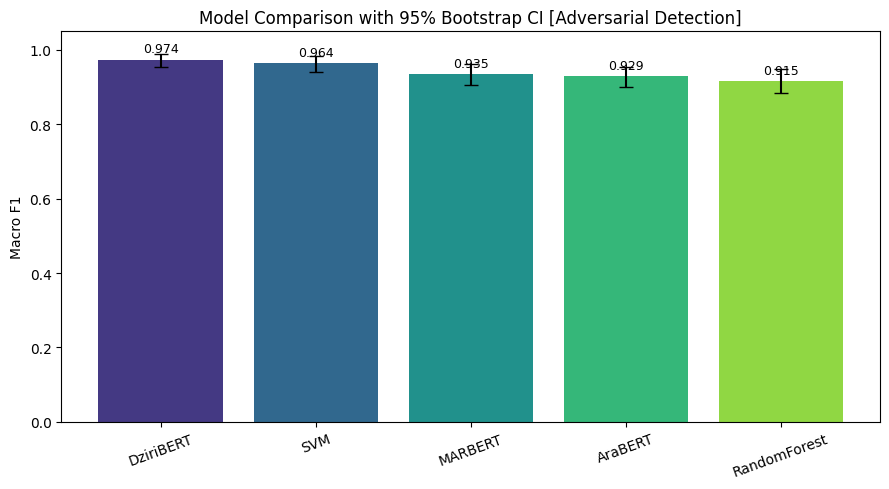

[adversarial] McNemar's DziriBERT vs SVM: b=8, c=5, p=0.5811 → ✗ not significant (α=0.05)
  → Revise RQ2 to state significance status (p=0.5811)


,Model A,Model B,"A right, B wrong","A wrong, B right",p (raw),p (Holm),"significant (Holm, α=0.05)"
0,DziriBERT,RandomForest,23,5,0.0013,0.0131,True
1,AraBERT,DziriBERT,3,17,0.0026,0.0232,True
2,SVM,RandomForest,19,4,0.0026,0.0232,True
3,MARBERT,DziriBERT,6,18,0.0227,0.1586,False
4,AraBERT,SVM,7,18,0.0455,0.2730,False
5,MARBERT,SVM,7,16,0.0931,0.4657,False
6,MARBERT,RandomForest,20,14,0.3912,1.0000,False
7,DziriBERT,SVM,8,5,0.5811,1.0000,False
8,AraBERT,RandomForest,23,19,0.6434,1.0000,False
9,MARBERT,AraBERT,12,10,0.8318,1.0000,False


Note: F1 95% CI and McNemar use the canonical-seed (42) predictions; F1 mean±std is over N_SEEDS seeds.


In [14]:
adversarial_summary_df = build_summary_table("adversarial")
display(adversarial_summary_df)
plot_macro_f1_ci_bar(adversarial_summary_df, "adversarial")

top2_adv = adversarial_summary_df["Model"].iloc[:2].tolist()
m1, m2 = top2_adv
pval = run_mcnemar(
    results["adversarial"][m1]["y_true"],
    results["adversarial"][m1]["y_pred"],
    results["adversarial"][m2]["y_pred"],
    model_a=m1, model_b=m2, task_key="adversarial"
)
print(f"  → Revise RQ2 to state significance status (p={pval:.4f})")

# All pairs, Holm-corrected (use THIS table for any significance claim beyond the top-2 pair)
pairwise_adversarial = pairwise_mcnemar_holm("adversarial")
display(pairwise_adversarial)
pairwise_adversarial.to_csv(f"{RESULTS_DIR}/adversarial_pairwise_mcnemar_holm.csv", index=False)
print("Note: F1 95% CI and McNemar use the canonical-seed (42) predictions; F1 mean±std is over N_SEEDS seeds.")

### 9.4 Per-Class P/R Table

In [15]:
best_adv = adversarial_summary_df["Model"].iloc[0]
pc_df = per_class_table(
    results["adversarial"][best_adv]["y_true"],
    results["adversarial"][best_adv]["y_pred"],
    "adversarial"
)
print(f"Per-class table — {best_adv} [adversarial]:")
display(pc_df)
pc_df.to_csv(f"{RESULTS_DIR}/adversarial_per_class_{best_adv}.csv")


Per-class table — DziriBERT [adversarial]:


,precision,recall,f1-score,support,n_test,note
class,,,,,,
benign,0.980392,0.967742,0.974026,155.0,155,
harmful,0.967949,0.980519,0.974194,154.0,154,


### 9.5 Confusion matrices

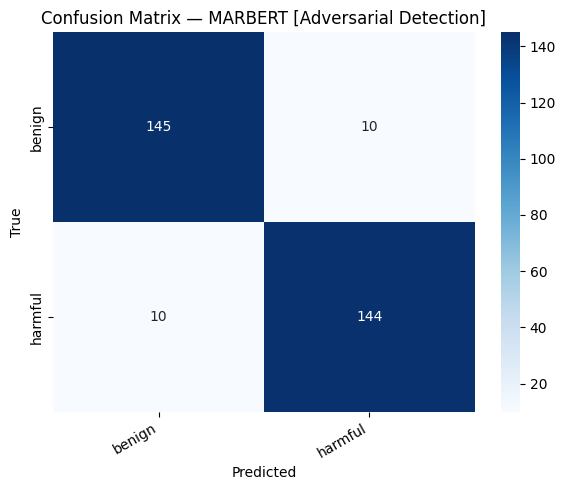

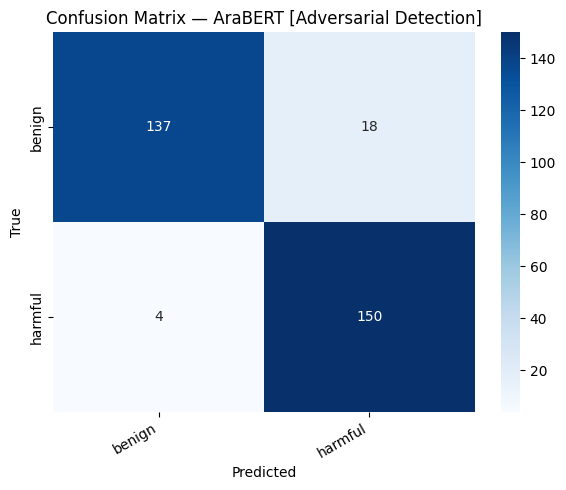

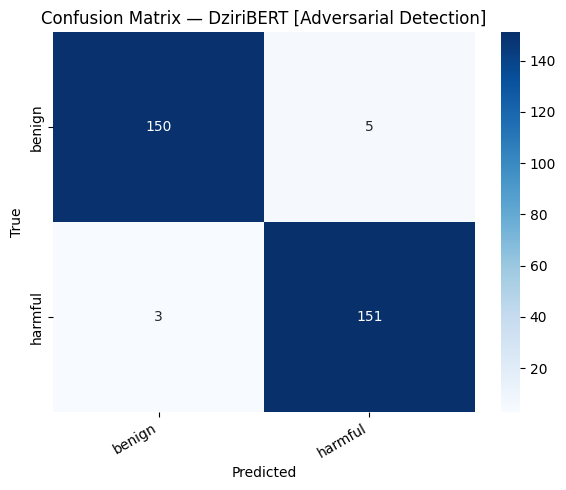

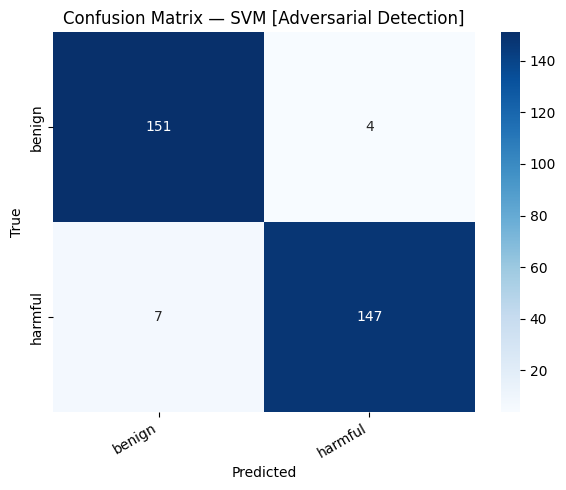

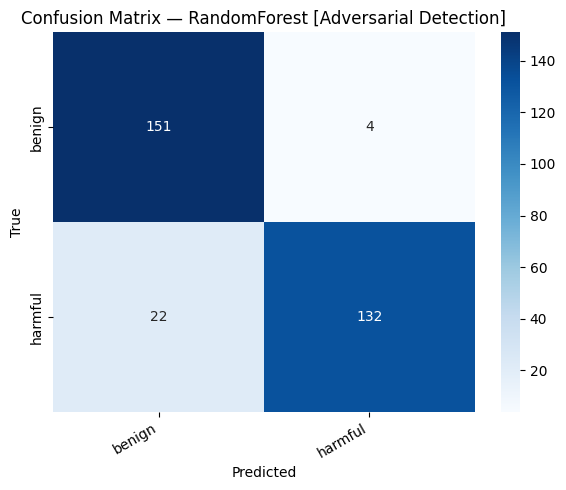

In [16]:
for model_key in results["adversarial"]:
    plot_confusion_matrix(results["adversarial"][model_key]["confusion_matrix"],
                          model_key, "adversarial")


## 10. Efficiency Comparison Table

In [17]:
rows = []
for task_key in TASKS:
    for model_key, m in results[task_key].items():
        rows.append({
            "Task": TASKS[task_key]["name"],
            "Model": model_key,
            "Macro F1": m["macro_f1"],
            "Train time (s)": m.get("train_time_s", "–"),
            "Model size (MB)": m.get("model_mb", "–"),
        })
efficiency_df = pd.DataFrame(rows)
efficiency_df.to_csv(f"{RESULTS_DIR}/efficiency_comparison.csv", index=False)
display(efficiency_df)


,Task,Model,Macro F1,Train time (s),Model size (MB)
0,Adversarial Detection,MARBERT,0.935274,114.00,651.400
1,Adversarial Detection,AraBERT,0.928676,84.70,540.800
2,Adversarial Detection,DziriBERT,0.974110,104.00,497.800
3,Adversarial Detection,SVM,0.964395,0.03,0.174
4,Adversarial Detection,RandomForest,0.915538,1.79,27.257


## 11. Per-Script Performance Breakdown

In [18]:
def evaluate_by_script(task_key):
    """Recompute Macro F1 per language_variant using already-saved predictions."""
    rows = []
    for model_key, m in results[task_key].items():
        y_true_all = np.array(m["y_true"])
        y_pred_all = np.array(m["y_pred"])
        for variant in test_df["language_variant"].unique():
            idx = test_df["language_variant"] == variant
            yt = y_true_all[idx.values]
            yp = y_pred_all[idx.values]
            if len(yt) == 0:
                continue
            _, _, f1, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
            rows.append({"Task": task_key, "Model": model_key,
                         "Script": variant, "n_test": len(yt), "Macro F1": round(f1, 4)})
    return pd.DataFrame(rows)

script_df = pd.concat([evaluate_by_script(tk) for tk in TASKS], ignore_index=True)
script_df.to_csv(f"{RESULTS_DIR}/per_script_performance.csv", index=False)
display(script_df)


,Task,Model,Script,n_test,Macro F1
0,adversarial,MARBERT,franco_arabic,81,1.0000
1,adversarial,MARBERT,arabizi,126,0.8393
2,adversarial,MARBERT,algerian_derja,102,1.0000
3,adversarial,AraBERT,franco_arabic,81,0.9753
4,adversarial,AraBERT,arabizi,126,0.8413
5,adversarial,AraBERT,algerian_derja,102,1.0000
6,adversarial,DziriBERT,franco_arabic,81,0.9753
7,adversarial,DziriBERT,arabizi,126,0.9600
8,adversarial,DziriBERT,algerian_derja,102,0.9900
9,adversarial,SVM,franco_arabic,81,0.9753


## 12. Save All Results

In [19]:
import json

def serialize_results(task_key):
    out = {}
    for model_name, m in results[task_key].items():
        out[model_name] = {
            "accuracy":  m["accuracy"],
            "precision": m["precision"],
            "recall":    m["recall"],
            "macro_f1":  m["macro_f1"],
            "f1_ci_low": m.get("f1_ci_low"),
            "f1_ci_high":m.get("f1_ci_high"),
            "macro_f1_mean": m.get("macro_f1_mean"),
            "macro_f1_std":  m.get("macro_f1_std"),
            "macro_f1_per_seed": m.get("macro_f1_per_seed"),
            "train_time_s":  m.get("train_time_s"),
            "model_mb":      m.get("model_mb"),
            "y_true": [int(v) for v in m["y_true"]],
            "y_pred": [int(v) for v in m["y_pred"]],
        }
    path = f"{RESULTS_DIR}/{task_key}_results.json"
    with open(path, "w") as f:
        json.dump(out, f)
    print(f"Saved {path}")

for tk in TASKS:
    serialize_results(tk)

Saved /kaggle/working/outputs/results/adversarial_results.json


In [20]:

import os
import shutil
from IPython.display import FileLink, display

RESULTS_DIR = "/kaggle/working/outputs/results"

shutil.make_archive(
    "/kaggle/working/task-b-adversarial-detection_results",
    "zip",
    RESULTS_DIR
)

display(FileLink("/task-b-adversarial-detection_results.zip"))


/task-b-adversarial-detection_results.zip